In [77]:
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from typing import TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI

In [78]:
load_dotenv()  # Load environment variables from .env file

True

In [79]:
llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0
)

In [80]:
class llmState(TypedDict):
    question : str
    answer : str

In [82]:
def llmQA(state: llmState) -> llmState:

    question = state['question']

    prompt = f"Answer the following question: {question}"

    answer = llm.invoke(prompt).content

    state['answer'] = answer

    return state

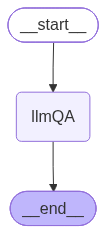

In [83]:
graph = StateGraph(llmState)

# add nodes to the graph
graph.add_node("llmQA", llmQA)

# add edges to the graph

graph.add_edge(START, "llmQA")
graph.add_edge("llmQA", END)

# compile 

workflow = graph.compile()

workflow

In [84]:
initial_state = {
    "question" : "define AI"}

final_state  = workflow.invoke(initial_state)
final_state

{'question': 'define AI',
 'answer': '**Artificial Intelligence (AI)** is a broad field of computer science focused on creating machines that can perform tasks that typically require human intelligence.\n\nIn essence, AI aims to enable computers to **simulate human cognitive functions** such as:\n\n*   **Learning:** Acquiring information and rules for using the information.\n*   **Reasoning:** Using rules to reach approximate or definite conclusions.\n*   **Problem-solving:** Finding solutions to complex challenges.\n*   **Perception:** Understanding and interpreting sensory input (like images, sounds, or text).\n*   **Decision-making:** Choosing the best course of action from available options.\n*   **Understanding natural language:** Processing and generating human language.\n*   **Adapting:** Adjusting to new situations and environments.\n\nAI systems achieve this by processing vast amounts of data, identifying patterns, and using algorithms to make predictions, recommendations, or 